# Predicting Smartphone Addiction

A reproducible, step-by-step binary-classification workflow: inspect the data, visualize missingness and relationships, validate without leakage, and expose an in-memory prediction function. This estimates the dataset's `addicted_label`; it is not a clinical diagnosis. No submission file is created.

## 1. Load libraries and data


In [9]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TARGET = 'addicted_label'
DATA_DIR = Path('data/raw')
TRAIN_PATH = DATA_DIR / 'train.csv'
TEST_PATH = DATA_DIR / 'test.csv'

if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f'Cannot find {TRAIN_PATH.resolve()}. Put train.csv in the notebook '
        'working directory or update DATA_DIR.'
    )
if not TEST_PATH.exists():
    raise FileNotFoundError(
        f'Cannot find {TEST_PATH.resolve()}. Put test.csv in the notebook '
        'working directory or update DATA_DIR.'
    )

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

if TARGET not in train_df.columns:
    raise KeyError(f'Training data must contain target column {TARGET!r}.')
if train_df[TARGET].isna().any():
    raise ValueError(f'Target column {TARGET!r} contains missing values.')
if train_df[TARGET].nunique() != 2:
    raise ValueError(
        f'This notebook expects a binary target; found '
        f'{train_df[TARGET].nunique()} distinct values.'
    )

FEATURES = [c for c in train_df.columns if c not in {'id', TARGET}]
missing_test_columns = sorted(set(FEATURES) - set(test_df.columns))
if missing_test_columns:
    raise ValueError(f'Test data is missing feature columns: {missing_test_columns}')
if not FEATURES:
    raise ValueError('No feature columns were found after excluding id and target.')

print(f'Train: {train_df.shape[0]:,} rows x {train_df.shape[1]} columns')
print(f'Test:  {test_df.shape[0]:,} rows x {test_df.shape[1]} columns')
print(f'Features: {len(FEATURES)}')
display(train_df.head())

Train: 691,369 rows x 14 columns
Test:  296,302 rows x 13 columns
Features: 12


,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


## 2. Inspect data types, ranges, and missing values

Check the target and feature distributions before choosing preprocessing. Missing rates below are calculated from the training data.

In [2]:
display(train_df.dtypes.rename('dtype').to_frame())
display(train_df.describe(include='all').T)

missing_summary = pd.DataFrame({
    'missing_count': train_df.isna().sum(),
    'missing_percent': train_df.isna().mean().mul(100),
}).sort_values('missing_percent', ascending=False)
display(missing_summary)
print('Duplicate rows:', train_df.duplicated().sum())
print('Target values:', sorted(train_df[TARGET].dropna().unique().tolist()))
display(train_df[TARGET].value_counts(dropna=False).sort_index().rename('rows').to_frame())

,dtype
id,int64
age,float64
daily_screen_time_hours,float64
social_media_hours,float64
gaming_hours,float64
work_study_hours,float64
sleep_hours,float64
notifications_per_day,float64
app_opens_per_day,float64
weekend_screen_time,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,691369.0,NaN,NaN,NaN,345684.0,199581.183467,0.0,172842.0,345684.0,518526.0,691368.0
age,662440.0,NaN,NaN,NaN,26.615408,5.153162,18.0,22.0,27.0,31.0,35.0
daily_screen_time_hours,595515.0,NaN,NaN,NaN,7.640865,2.721446,0.5,5.48,7.77,9.84,15.0
social_media_hours,557374.0,NaN,NaN,NaN,2.471038,1.316137,0.0,1.45,2.31,3.37,8.0
gaming_hours,564548.0,NaN,NaN,NaN,1.459265,0.934552,0.0,0.7,1.33,2.09,4.0
work_study_hours,639851.0,NaN,NaN,NaN,2.366971,1.258797,0.0,1.36,2.2,3.2,6.0
sleep_hours,646889.0,NaN,NaN,NaN,6.804334,1.234512,4.5,5.78,6.8,7.87,9.0
notifications_per_day,623785.0,NaN,NaN,NaN,145.8949,65.917556,20.0,93.0,150.0,204.0,250.0
app_opens_per_day,610659.0,NaN,NaN,NaN,102.636781,48.09397,15.0,64.0,104.0,145.0,180.0
weekend_screen_time,579306.0,NaN,NaN,NaN,9.479866,2.856006,0.51,7.28,9.58,11.75,17.56


,missing_count,missing_percent
social_media_hours,133995,19.381112
gaming_hours,126821,18.343461
weekend_screen_time,112063,16.208855
daily_screen_time_hours,95854,13.864376
app_opens_per_day,80710,11.673940
notifications_per_day,67584,9.775388
stress_level,55148,7.976638
work_study_hours,51518,7.451592
sleep_hours,44480,6.433612
academic_work_impact,44224,6.396584


Duplicate rows: 0
Target values: [0, 1]


,rows
addicted_label,
0,200895
1,490474


## 3. Visualize missingness, class balance, and feature relationships

The missingness heatmap uses a fixed-size random sample for readability. Boxplots omit fliers for display only; no observations are removed from training.

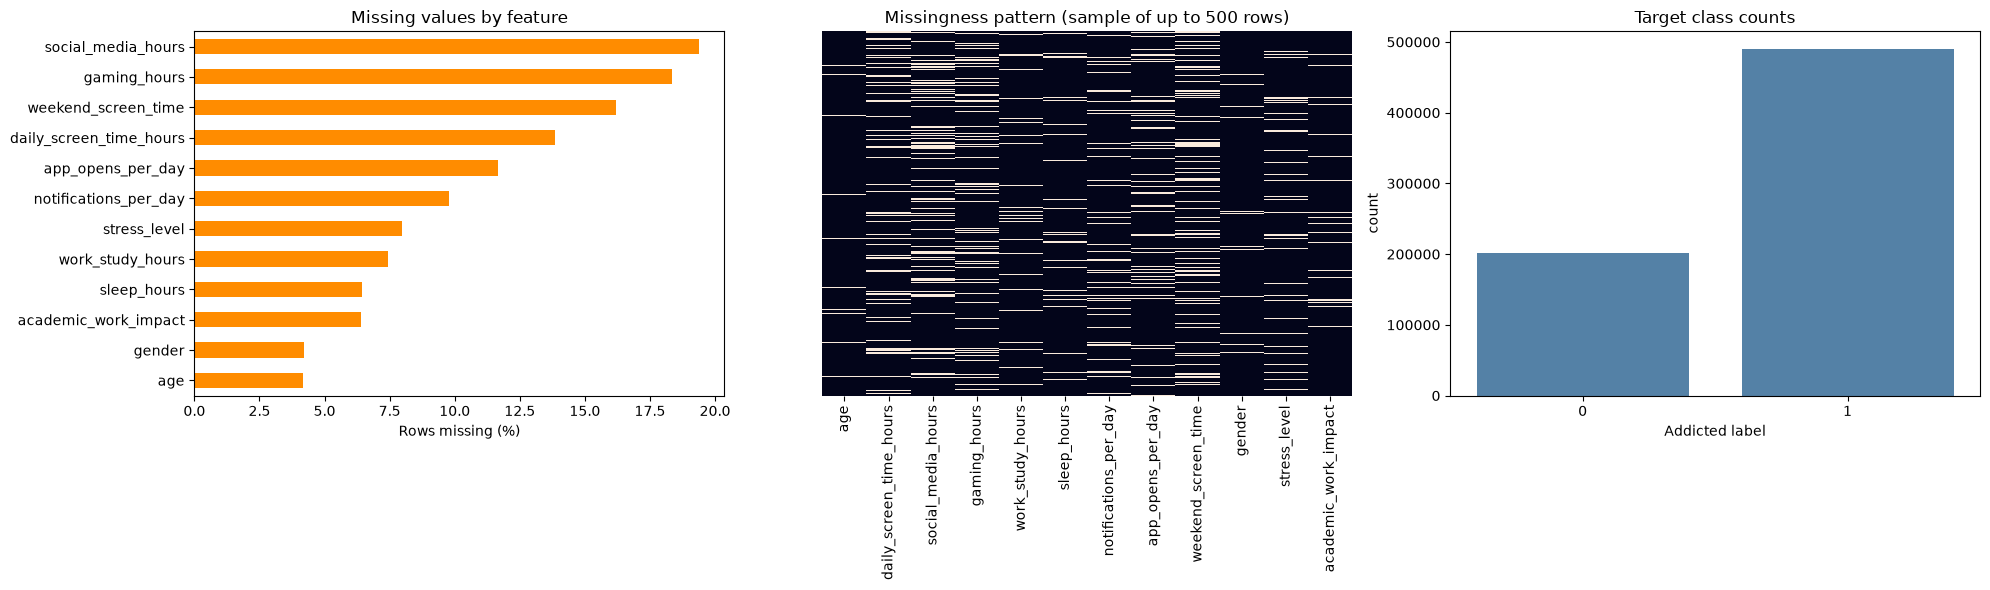

Target proportions:


,proportion
addicted_label,
0,0.290576
1,0.709424


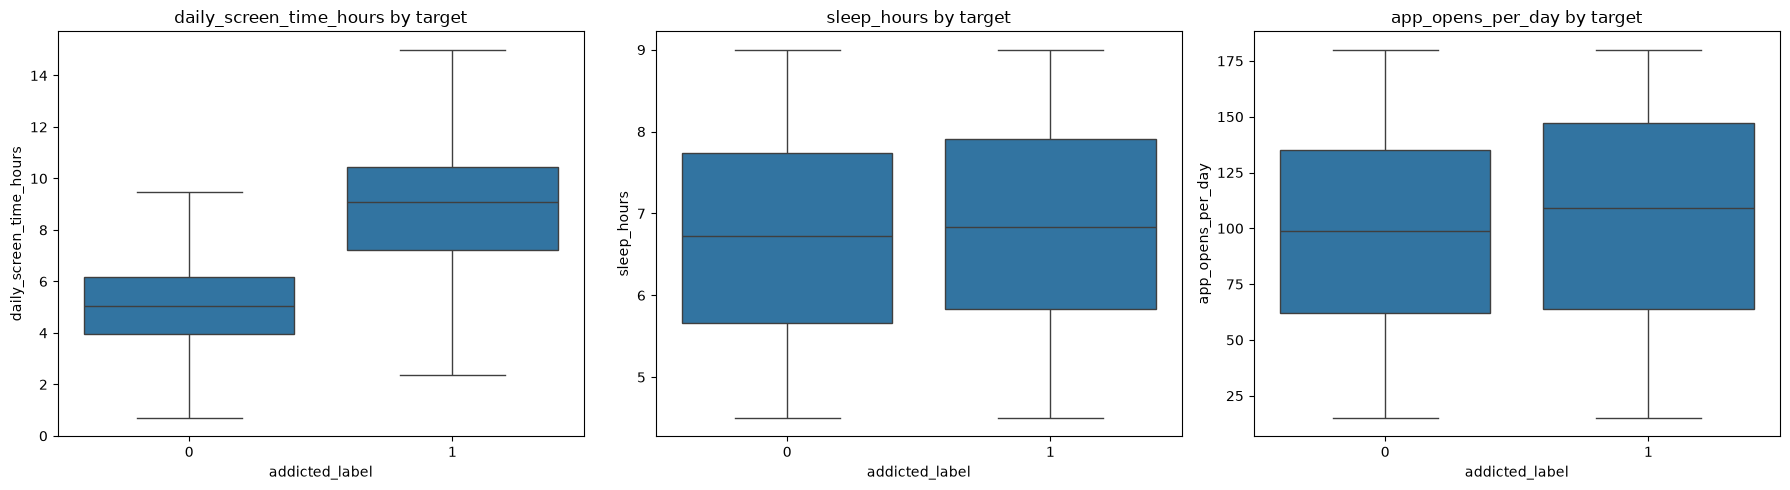

In [3]:
missing_percent = train_df[FEATURES].isna().mean().mul(100).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
missing_percent.plot.barh(ax=axes[0], color='darkorange')
axes[0].set(title='Missing values by feature', xlabel='Rows missing (%)')

missing_sample = train_df[FEATURES].sample(
    min(500, len(train_df)), random_state=RANDOM_STATE
)
sns.heatmap(missing_sample.isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title('Missingness pattern (sample of up to 500 rows)')

sns.countplot(data=train_df, x=TARGET, ax=axes[2], color='steelblue')
axes[2].set(title='Target class counts', xlabel='Addicted label')
plt.tight_layout()
plt.show()

print('Target proportions:')
display(train_df[TARGET].value_counts(normalize=True).sort_index().rename('proportion').to_frame())

relationship_candidates = [
    'daily_screen_time_hours', 'sleep_hours', 'app_opens_per_day'
]
relationship_features = [
    c for c in relationship_candidates
    if c in train_df.columns and pd.api.types.is_numeric_dtype(train_df[c])
]
if relationship_features:
    fig, axes = plt.subplots(
        1, len(relationship_features),
        figsize=(6 * len(relationship_features), 5),
        squeeze=False
    )
    for ax, column in zip(axes.ravel(), relationship_features):
        sns.boxplot(data=train_df, x=TARGET, y=column, showfliers=False, ax=ax)
        ax.set_title(f'{column} by target')
    plt.tight_layout()
    plt.show()
else:
    print('None of the example numeric relationship columns are present; skipping boxplots.')

## 4. Split the data and handle missing values

Split before learning category levels, and stratify to preserve the class ratio. The model accepts missing numeric values natively. Missing categorical values are given a `Missing` category. Category levels are learned on the training fold only; previously unseen values become missing for the model. We exclude `id` because it identifies rows rather than describing phone use. No global imputation or scaling is used.

In [4]:
X = train_df[FEATURES].copy()
target_classes = sorted(train_df[TARGET].unique().tolist())
target_to_int = {label: index for index, label in enumerate(target_classes)}
y = train_df[TARGET].map(target_to_int).astype('int8')

categorical_columns = X.select_dtypes(
    include=['object', 'str', 'category', 'bool']
).columns.tolist()

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

def category_levels_from(data):
    return {
        column: pd.Index(data[column].fillna('Missing').astype(str).unique())
        for column in categorical_columns
    }

def prepare_features(data, category_levels):
    prepared = data[FEATURES].copy()
    for column in categorical_columns:
        values = prepared[column].fillna('Missing').astype(str)
        prepared[column] = pd.Categorical(
            values, categories=category_levels[column]
        )
    return prepared

validation_categories = category_levels_from(X_train)
X_train_prepared = prepare_features(X_train, validation_categories)
X_valid_prepared = prepare_features(X_valid, validation_categories)
print('Target encoding:', target_to_int)
print('Categorical columns:', categorical_columns)
print('Numeric missing values are retained for the estimator to handle.')
print('Categorical missing values use the explicit Missing category.')

Target encoding: {0: 0, 1: 1}
Categorical columns: ['gender', 'stress_level', 'academic_work_impact']
Numeric missing values are retained for the estimator to handle.
Categorical missing values use the explicit Missing category.


## 5. Train and evaluate the baseline model

Histogram gradient boosting is the baseline classifier. It supports missing numeric values and categorical features in recent scikit-learn versions. The metrics below are calculated only on the held-out validation fold. No expected score is assumed: use the values produced by your own run.

,value
iterations,300.000000
majority-class baseline accuracy,0.709425
ROC-AUC,0.960540
PR-AUC,0.984048
accuracy at threshold 0.5,0.897298
balanced accuracy at threshold 0.5,0.871682
precision at threshold 0.5,0.923194
recall at threshold 0.5,0.932841
F1 at threshold 0.5,0.927992


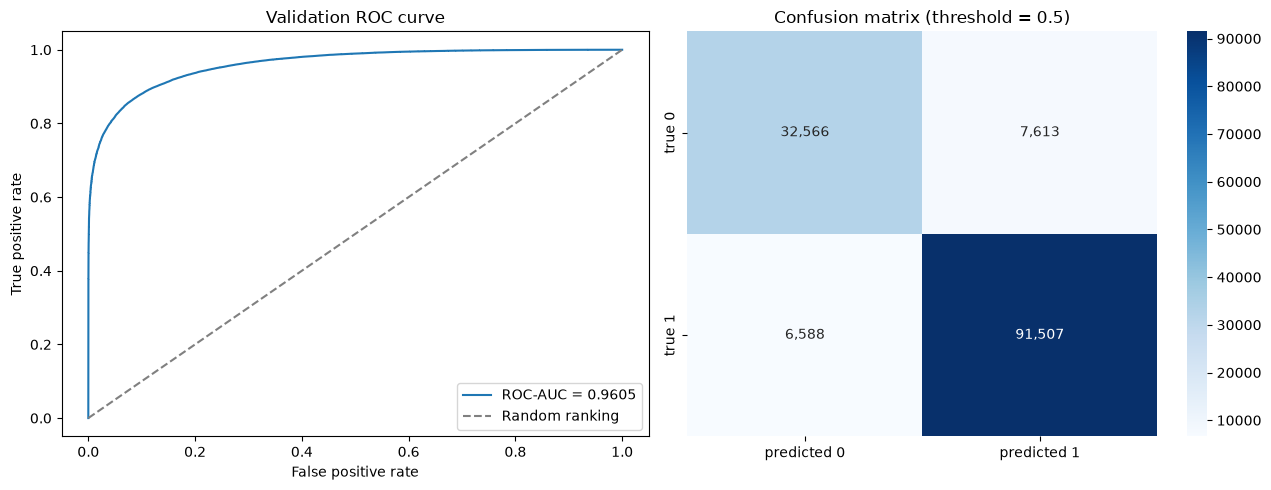

In [5]:
validation_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.1,
    max_leaf_nodes=31,
    min_samples_leaf=30,
    l2_regularization=1.0,
    categorical_features='from_dtype',
    early_stopping=True,
    n_iter_no_change=20,
    random_state=RANDOM_STATE,
)
validation_model.fit(X_train_prepared, y_train)

valid_probability = validation_model.predict_proba(X_valid_prepared)[:, 1]
valid_prediction = (valid_probability >= 0.5).astype('int8')
validation_metrics = pd.Series({
    'iterations': validation_model.n_iter_,
    'majority-class baseline accuracy': y_valid.value_counts(normalize=True).max(),
    'ROC-AUC': roc_auc_score(y_valid, valid_probability),
    'PR-AUC': average_precision_score(y_valid, valid_probability),
    'accuracy at threshold 0.5': accuracy_score(y_valid, valid_prediction),
    'balanced accuracy at threshold 0.5': balanced_accuracy_score(y_valid, valid_prediction),
    'precision at threshold 0.5': precision_score(y_valid, valid_prediction),
    'recall at threshold 0.5': recall_score(y_valid, valid_prediction),
    'F1 at threshold 0.5': f1_score(y_valid, valid_prediction),
})
display(validation_metrics.to_frame('value'))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
false_positive_rate, true_positive_rate, _ = roc_curve(y_valid, valid_probability)
axes[0].plot(false_positive_rate, true_positive_rate,
             label=f"ROC-AUC = {validation_metrics['ROC-AUC']:.4f}")
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
axes[0].set(title='Validation ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[0].legend(loc='lower right')
sns.heatmap(confusion_matrix(y_valid, valid_prediction), annot=True, fmt=',d', cmap='Blues',
            xticklabels=['predicted 0', 'predicted 1'],
            yticklabels=['true 0', 'true 1'], ax=axes[1])
axes[1].set_title('Confusion matrix (threshold = 0.5)')
plt.tight_layout()
plt.show()

## 6. Compare classifiers and select the best

Compare Decision Tree, Random Forest, and the Histogram Gradient Boosting baseline. XGBoost and CatBoost are included when their packages are installed; otherwise they are skipped with a clear message. All candidate models use the same stratified validation split and the same preprocessing pipeline. The best model is selected by ROC-AUC, while the remaining metrics should also be reviewed before use.

In [6]:
from time import perf_counter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

try:
    one_hot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown='ignore', sparse=False)

transformers = []
if numeric_features:
    transformers.append((
        'numeric',
        Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]),
        numeric_features,
    ))
if categorical_features:
    transformers.append((
        'categorical',
        Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', one_hot),
        ]),
        categorical_features,
    ))

model_preprocessor = ColumnTransformer(
    transformers=transformers, remainder='drop'
)

candidate_models = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=14, min_samples_leaf=20, random_state=RANDOM_STATE,
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=16, min_samples_leaf=5,
        class_weight='balanced_subsample', n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}

# Optional libraries: do not stop the notebook if either is unavailable.
try:
    from xgboost import XGBClassifier
    candidate_models['XGBoost'] = XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, tree_method='hist',
        eval_metric='logloss', n_jobs=-1, random_state=RANDOM_STATE,
    )
except ImportError:
    print('XGBoost not installed; skipping it.')

try:
    from catboost import CatBoostClassifier
    candidate_models['CatBoost'] = CatBoostClassifier(
        iterations=200, depth=6, learning_rate=0.1,
        verbose=False, thread_count=-1, random_seed=RANDOM_STATE,
        allow_writing_files=False,
    )
except ImportError:
    print('CatBoost not installed; skipping it.')

model_pipelines = {}
comparison_rows = []

def add_comparison_row(model_name, probabilities, fit_seconds):
    predictions = (probabilities >= 0.5).astype('int8')
    comparison_rows.append({
        'Model': model_name,
        'ROC-AUC': roc_auc_score(y_valid, probabilities),
        'PR-AUC': average_precision_score(y_valid, probabilities),
        'Accuracy': accuracy_score(y_valid, predictions),
        'Balanced accuracy': balanced_accuracy_score(y_valid, predictions),
        'Precision': precision_score(y_valid, predictions, zero_division=0),
        'Recall': recall_score(y_valid, predictions, zero_division=0),
        'F1': f1_score(y_valid, predictions, zero_division=0),
        'Fit seconds': fit_seconds,
    })

for model_name, estimator in candidate_models.items():
    pipeline = Pipeline([
        ('preprocessor', clone(model_preprocessor)),
        ('classifier', estimator),
    ])
    start_time = perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = perf_counter() - start_time
    model_pipelines[model_name] = pipeline
    add_comparison_row(
        model_name, pipeline.predict_proba(X_valid)[:, 1], fit_seconds,
    )

add_comparison_row(
    'HistGradientBoosting (existing)', valid_probability, np.nan
)
model_comparison = (
    pd.DataFrame(comparison_rows)
    .set_index('Model')
    .sort_values('ROC-AUC', ascending=False)
)
best_model_name = model_comparison.index[0]
best_model_metrics = model_comparison.loc[best_model_name]
display(model_comparison)
print(
    f"Best validation model by ROC-AUC: {best_model_name} "
    f"(ROC-AUC={best_model_metrics['ROC-AUC']:.4f}, "
    f"PR-AUC={best_model_metrics['PR-AUC']:.4f})"
)

best_validation_probability = (
    valid_probability
    if best_model_name == 'HistGradientBoosting (existing)'
    else model_pipelines[best_model_name].predict_proba(X_valid)[:, 1]
)
best_validation_prediction = (
    best_validation_probability >= 0.5
).astype('int8')
print(classification_report(
    y_valid, best_validation_prediction,
    target_names=['not addicted', 'addicted'], zero_division=0,
))
display(pd.DataFrame(
    confusion_matrix(y_valid, best_validation_prediction),
    index=['true not addicted', 'true addicted'],
    columns=['predicted not addicted', 'predicted addicted'],
))

,ROC-AUC,PR-AUC,Accuracy,Balanced accuracy,Precision,Recall,F1,Fit seconds
Model,,,,,,,,
HistGradientBoosting (existing),0.960540,0.984048,0.897298,0.871682,0.923194,0.932841,0.927992,NaN
XGBoost,0.948150,0.979047,0.879392,0.851075,0.911959,0.918681,0.915308,30.502450
CatBoost,0.947315,0.978523,0.878560,0.848365,0.909459,0.920455,0.914924,38.602577
Random Forest,0.938263,0.975014,0.839905,0.857843,0.952454,0.815016,0.878392,149.545632
Decision Tree,0.929352,0.968781,0.858274,0.814392,0.885429,0.919160,0.901979,20.298750


Best validation model by ROC-AUC: HistGradientBoosting (existing) (ROC-AUC=0.9605, PR-AUC=0.9840)
              precision    recall  f1-score   support

not addicted       0.83      0.81      0.82     40179
    addicted       0.92      0.93      0.93     98095

    accuracy                           0.90    138274
   macro avg       0.88      0.87      0.87    138274
weighted avg       0.90      0.90      0.90    138274



,predicted not addicted,predicted addicted
true not addicted,32566,7613
true addicted,6588,91507


## 7. Refit the selected model and predict in memory

Refit the model selected by validation on all labeled training rows. `predict_addiction()` accepts a DataFrame containing the feature columns and returns a positive-class probability per row. Integrate this function with your deployment environment. This notebook intentionally does not write `submission.csv` or another prediction file.

In [7]:
production_uses_raw_features = best_model_name != 'HistGradientBoosting (existing)'
if production_uses_raw_features:
    production_model = clone(model_pipelines[best_model_name])
    production_model.fit(X, y)
else:
    production_categories = category_levels_from(X)
    X_full_prepared = prepare_features(X, production_categories)
    production_model = HistGradientBoostingClassifier(
        max_iter=max(1, validation_model.n_iter_),
        learning_rate=0.1,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        l2_regularization=1.0,
        categorical_features='from_dtype',
        early_stopping=False,
        random_state=RANDOM_STATE,
    )
    production_model.fit(X_full_prepared, y)

def predict_addiction(records):
    """Return estimated probability of target class 1 for each input row."""
    if not isinstance(records, pd.DataFrame):
        raise TypeError('records must be a pandas DataFrame.')
    missing_features = sorted(set(FEATURES) - set(records.columns))
    if missing_features:
        raise ValueError(
            f'Missing required feature columns: {missing_features}'
        )
    prepared = (
        records[FEATURES].copy()
        if production_uses_raw_features
        else prepare_features(records, production_categories)
    )
    probabilities = production_model.predict_proba(prepared)[:, 1]
    return pd.Series(
        probabilities, index=records.index, name='addiction_probability'
    )

example = test_df.head().copy()
example_predictions = pd.DataFrame({
    'addiction_probability': predict_addiction(example),
})
if 'id' in example.columns:
    example_predictions.insert(0, 'id', example['id'])
display(example_predictions)
print(
    'Probability interpretation: values closer to 1 indicate a higher '
    'model-estimated likelihood of target class 1; this is not a diagnosis.'
)

,id,addiction_probability
0,691369,0.998157
1,691370,0.955063
2,691371,0.955569
3,691372,0.984077
4,691373,0.996004


Probability interpretation: values closer to 1 indicate a higher model-estimated likelihood of target class 1; this is not a diagnosis.


## 8. Final checks and how to use the model

The following checks verify that the fitted model is usable and that the prediction function returns valid probabilities. They do not replace evaluation on a genuinely separate dataset.



In [8]:
# Final model and prediction-function checks
assert callable(predict_addiction)
assert len(FEATURES) > 0
assert best_model_name in model_comparison.index

check_rows = test_df.head(min(10, len(test_df))).copy()
check_probabilities = predict_addiction(check_rows)
assert len(check_probabilities) == len(check_rows)
assert check_probabilities.notna().all()
assert check_probabilities.between(0, 1).all()

print('Notebook workflow completed successfully.')
print(f'Selected model: {best_model_name}')
print(f'Validation ROC-AUC: {best_model_metrics["ROC-AUC"]:.5f}')
print(f'Validation PR-AUC: {best_model_metrics["PR-AUC"]:.5f}')
print(f'Prediction sanity check: {len(check_probabilities)} rows, all probabilities in [0, 1].')
print('No prediction file was written; predictions remain in memory.')

Notebook workflow completed successfully.
Selected model: HistGradientBoosting (existing)
Validation ROC-AUC: 0.96054
Validation PR-AUC: 0.98405
Prediction sanity check: 10 rows, all probabilities in [0, 1].
No prediction file was written; predictions remain in memory.
